# Holdout

This notebook records the one opening of the holdout under `configs/holdout.yaml`: 2022-01-03 to 2026-10-23, 1,207 trading days that no earlier work in this project touched. The three books and their outcome rules were committed before any holdout row was read, and nothing here chooses or tunes anything.

Results are read from `reports/holdout/`, and the summary is in `reports/holdout/SUMMARY.md`.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

OUT = Path("../reports/holdout")
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
DATA = Path("../data/processed/holdout")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)
COLORS = {"headline": "#2a78d6", "benchmark": "#eb6834", "candidate": "#1baf7a"}
NAMES = {"headline": "headline (LightGBM)", "benchmark": "benchmark (B0)", "candidate": "candidate (LightGBM top 25%)"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
books = pd.read_csv(OUT / "books.csv")
difference = pd.read_csv(OUT / "lightgbm_minus_b0.csv")
by_year = pd.read_csv(OUT / "by_year.csv")
display(pd.read_csv(OUT / "checks.csv"))
{**json.loads((OUT / "opened.json").read_text()), **{k: v for k, v in json.loads((OUT / "run_metadata.json").read_text()).items()
                                                     if k in ("last_score_date", "last_engine_date", "runtime_seconds")}}

,check,book,value,limit,passed
0,predictions_lightgbm_h5_rank,all,1.749393e-09,0.000010,True
1,predictions_B0_reversal_h5,all,0.000000e+00,0.000010,True
2,recorded_net_sharpe,headline,2.775558e-17,0.000001,True
3,recorded_net_sharpe,benchmark,0.000000e+00,0.000001,True
4,recorded_net_sharpe,candidate,0.000000e+00,0.000001,True


{'opened_at': '2026-10-30T14:45:22+00:00',
 'config_commit': 'acbf5a9eaa2f0efb5292122505751f5e99ca371e',
 'config_dirty': False,
 'config_sha256': 'fb87c8a5751803c2f8f0e60ab34427bc089a86d67ffd967bc46c938523ad9fca',
 'code_commit': '6f731f9fe42329af477250c618210818353b562d',
 'code_dirty': False,
 'features_config_sha256': '42109759ae31f519774ae5ebdcdf59468732ed5eb2511704420bf1ed47fc136d',
 'panel_sha256': '747c69f3ea849f522e4f3e277de4771ea9d79c794be27425f89eb25f8cd6ee4c',
 'panel_bytes': 649981296,
 'last_score_date': '2026-10-15',
 'last_engine_date': '2026-10-23',
 'runtime_seconds': 6675.3}

## The declared outcomes

Both primary outcomes are null. The headline is `inconclusive` at 0.21 net (t 0.48), and its interval, -0.58 to 1.01, contains both zero and the tuning figure of 0.35. The difference from B0 is `no_difference_shown`: +0.83, with an interval of -0.33 to 2.02. The candidate, which is secondary, is `inconclusive` at 0.25 net (t 0.53).

An `inconclusive` label doesn't show the books have no edge. With about 4.8 years, a t of 2 needs a net Sharpe near 0.9, so this sample can't separate zero from a modest edge.

,book,role,net_sharpe,net_nw_t,net_sharpe_ci_low,net_sharpe_ci_high,outcome
0,headline,primary,0.21,0.48,-0.58,1.01,inconclusive
1,benchmark,comparator,-0.61,-1.41,-1.43,0.17,NaN
2,candidate,second_round_candidate,0.25,0.53,-0.63,1.06,inconclusive


,test,difference,ci_low,ci_high,resample_sd,share_above_zero,contains_zero,outcome
0,lightgbm_minus_b0,0.83,-0.33,2.02,0.59,0.92,True,no_difference_shown


,tuning,evaluation,holdout
headline,0.35,-0.00,0.21
benchmark,0.45,-0.03,-0.61
candidate,0.62,0.38,0.25


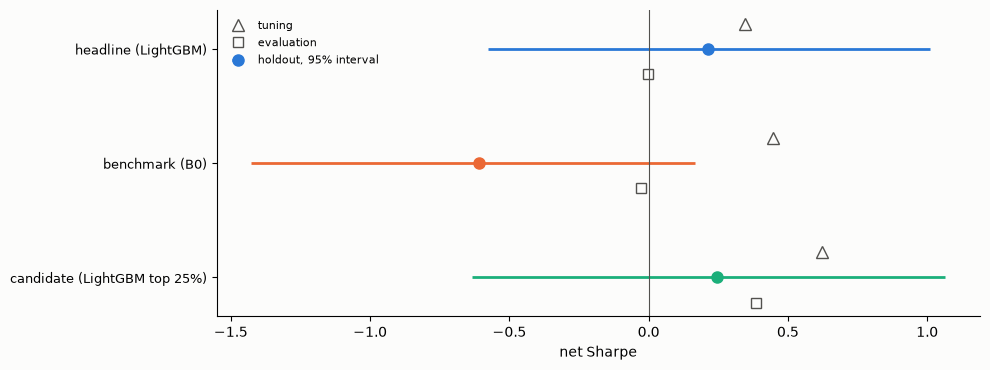

In [2]:
portfolio = pd.read_csv("../reports/portfolio/summary.csv").query("construction == 'optimised' and scenario == 'base'")
second = pd.read_csv("../reports/second_round/evaluation.csv").query("variant == 'liquid_universe__lightgbm_h5_rank__optimised__0.25'").iloc[0]
earlier = {"headline": portfolio.query("signal == 'lightgbm_h5_rank'").set_index("window")["net_sharpe"].to_dict(),
           "benchmark": portfolio.query("signal == 'B0_reversal_h5'").set_index("window")["net_sharpe"].to_dict(),
           "candidate": {"tuning": second["tuning_net_sharpe"], "evaluation": second["net_sharpe"]}}
fig, ax = plt.subplots(figsize=(10, 3.8))
y = {k: i for i, k in enumerate(books["book"])}
for _, row in books.iterrows():
    i = y[row["book"]]
    ax.errorbar(row["net_sharpe"], i, xerr=[[row["net_sharpe"] - row["net_sharpe_ci_low"]], [row["net_sharpe_ci_high"] - row["net_sharpe"]]],
                fmt="o", ms=8, lw=2, color=COLORS[row["book"]], label="holdout, 95% interval" if i == 0 else None)
    ax.plot(earlier[row["book"]]["tuning"], i - 0.22, "^", ms=8, mfc="none", color="#52514e", label="tuning" if i == 0 else None)
    ax.plot(earlier[row["book"]]["evaluation"], i + 0.22, "s", ms=7, mfc="none", color="#52514e", label="evaluation" if i == 0 else None)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(list(y.values()), [NAMES[k] for k in y], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("net Sharpe")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "holdout_intervals.png", dpi=150)
display(books[["book", "role", "net_sharpe", "net_nw_t", "net_sharpe_ci_low", "net_sharpe_ci_high", "outcome"]].round(2))
display(difference.round(2))
display(pd.DataFrame(earlier).T.join(books.set_index("book")["net_sharpe"].rename("holdout"))[["tuning", "evaluation", "holdout"]].round(2))

## What the books did

LightGBM's gross Sharpe of 0.34 is above the 0.14 of the evaluation window, and it trades 0.85× a year, so costs take little. But the book is small: mean gross 1.13, 1.7% vol and about 36 bp a year net. The candidate is smaller still, at mean gross 0.16 and about 15 bp a year.

B0 loses before costs (gross -0.30), and costs of about 209 bp a year take it to -0.61 net. Its realised beta to the equal-weighted universe is 0.13 (t 6.6), much as in the earlier windows, so it isn't market-neutral in practice. Its interval still contains zero.

book,headline,benchmark,candidate
net_sharpe,0.2146,-0.6105,0.2460
gross_sharpe,0.3413,-0.3025,0.3146
net_return_ann,0.0036,-0.0463,0.0015
net_vol_ann,0.0169,0.0758,0.0059
cost_ann,0.0007,0.0209,0.0002
borrow_ann,0.0014,0.0025,0.0002
annual_turnover,0.8471,13.6110,0.2811
breakeven_cost_multiplier,2.6932,-0.9816,4.5811
breakeven_impact_y,12.6014,-2.2867,20.8343
breakeven_borrow_bps_per_year,89.4774,-444.3000,213.3705


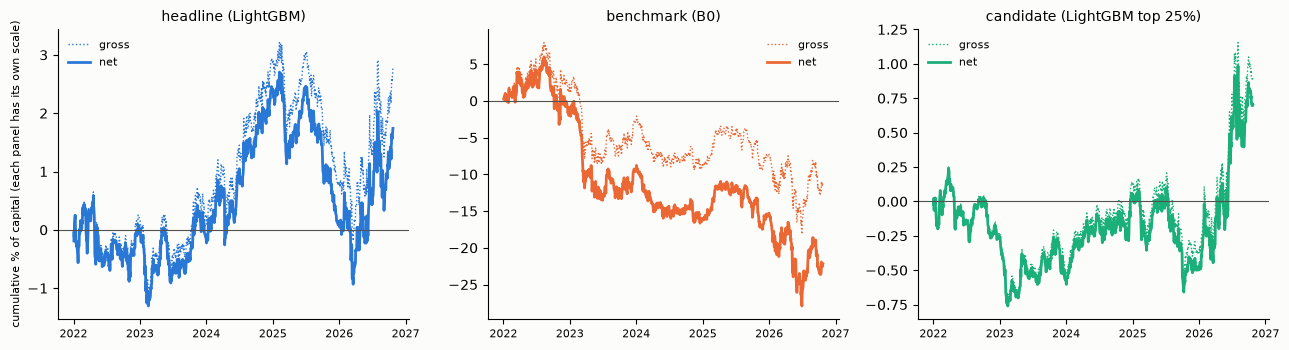

In [3]:
cols = ["book", "net_sharpe", "gross_sharpe", "net_return_ann", "net_vol_ann", "cost_ann", "borrow_ann", "annual_turnover", "breakeven_cost_multiplier",
        "breakeven_impact_y", "breakeven_borrow_bps_per_year", "max_drawdown", "mean_gross_exposure", "realised_beta", "realised_beta_t"]
display(books[cols].set_index("book").T.round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, COLORS):
    d = pd.read_parquet(DATA / f"{name}.parquet", columns=["date", "net_pnl", "gross_pnl"])
    d = d.assign(date=pd.to_datetime(d["date"])).set_index("date").loc["2022-01-01":]
    ax.plot(100 * d["gross_pnl"].cumsum(), color=COLORS[name], lw=1, ls=":", label="gross")
    ax.plot(100 * d["net_pnl"].cumsum(), color=COLORS[name], lw=2, label="net")
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_title(NAMES[name], fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("cumulative % of capital (each panel has its own scale)")
axes[0].yaxis.label.set_size(8)
fig.tight_layout()
fig.savefig(FIG / "cumulative_returns.png", dpi=150)

## Year by year

No book is steady. The two LightGBM books move together: flat or down in 2022 and 2023, up in 2024, down in 2025 and up in 2026. The headline made +2.4% in 2024 and lost 2.3% in 2025.

Nearly all of the LightGBM return arrives in 2026. The headline had made +0.10% by the end of 2025, out of +1.74% in total, and the candidate was at -0.50%, out of +0.70%. Without its single best month, each book's Sharpe is about zero. This table is descriptive and wasn't declared, and it reads only the recorded daily series. B0's worst stretch came early: -11.8% over the 42 days to 2023-03-23.

book,headline,benchmark,candidate
year,,,
2022,-0.00,-0.12,-0.58
2023,-0.06,-1.05,-0.72
2024,1.55,-1.27,1.33
2025,-1.54,0.15,-1.02
2026,0.81,-0.81,1.44


book,headline,benchmark,candidate
year,,,
2022,-0.0000,-0.0099,-0.0026
2023,-0.0008,-0.0838,-0.0029
2024,0.0244,-0.0664,0.0059
2025,-0.0226,0.0073,-0.0054
2026,0.0164,-0.0688,0.0120


,total,to end of 2025,2026,best month,best month return,Sharpe without best month
headline,0.017392,0.000955,0.016437,2026-07,0.01515,0.029034
benchmark,-0.221574,-0.152805,-0.068769,2026-07,0.050351,-0.766083
candidate,0.007004,-0.004972,0.011976,2026-06,0.006932,0.002731


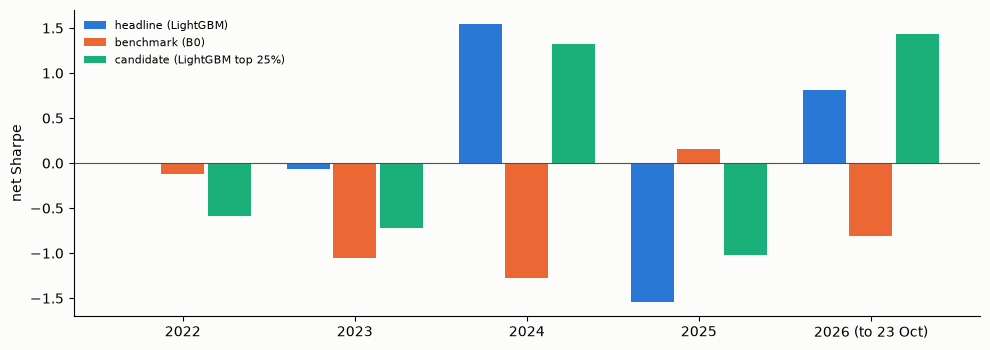

In [4]:
years = sorted(by_year["year"].unique())
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, name in enumerate(COLORS):
    g = by_year[by_year["book"] == name].set_index("year").reindex(years)
    ax.bar(np.arange(len(years)) + (i - 1) * 0.27, g["net_sharpe"], 0.25, color=COLORS[name], label=NAMES[name])
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(np.arange(len(years)), [f"{y} (to 23 Oct)" if y == 2026 else str(y) for y in years])
ax.set_ylabel("net Sharpe")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "by_year.png", dpi=150)
display(by_year.pivot(index="year", columns="book", values="net_sharpe")[list(COLORS)].round(2))
display(by_year.pivot(index="year", columns="book", values="net_return")[list(COLORS)].round(4))
rows = {}
for name in COLORS:
    net = pd.read_parquet(DATA / f"{name}.parquet", columns=["date", "net_pnl"])
    net = net.assign(date=pd.to_datetime(net["date"])).set_index("date").loc["2022-01-01":, "net_pnl"]
    months = net.groupby(net.index.to_period("M")).sum()
    rest = net[net.index.to_period("M") != months.idxmax()]
    rows[name] = {"total": net.sum(), "to end of 2025": net[:"2025-12-31"].sum(), "2026": net["2026"].sum(), "best month": str(months.idxmax()),
                  "best month return": months.max(), "Sharpe without best month": rest.mean() / rest.std() * 252 ** 0.5}
display(pd.DataFrame(rows).T.round(4))

## The model

The score kept its ranking power. Its daily IC is 0.018 (t 2.25, secondary), close to the 0.017 of 2007-2021. So the model's content didn't vanish on new data, but the book still can't turn it into a return this sample can distinguish from zero. That's the same gap the first portfolio results showed.

The January refits chose their settings by the unchanged rule. The first of them stopped after 5 boosting rounds, and the validation ICs range from 0.010 to 0.023.

In [5]:
research = pd.read_csv("../reports/models/ic_summary.csv").query("column == 'lightgbm_h5_rank'")[["n_dates", "ic_mean", "nw_t"]].assign(window="2007-2021 out of sample")
display(pd.concat([research, pd.read_csv(OUT / "model_ic.csv").rename(columns={"n_days": "n_dates", "mean_ic": "ic_mean"})[["n_dates", "ic_mean", "nw_t"]].assign(window="holdout")])[["window", "n_dates", "ic_mean", "nw_t"]].round(4))
display(pd.read_csv(OUT / "refit_hyperparameters.csv")[["fold_id", "num_leaves", "min_data_in_leaf", "lambda_l2", "learning_rate", "feature_fraction", "validation_ic", "n_rounds", "test_rows"]].round(4))

,window,n_dates,ic_mean,nw_t
5,2007-2021 out of sample,3755,0.0174,3.4956
0,holdout,1201,0.0181,2.2548


,fold_id,num_leaves,min_data_in_leaf,lambda_l2,learning_rate,feature_fraction,validation_ic,n_rounds,test_rows
0,15,15,10000,50.0,0.05,0.7,0.0102,5,126430
1,16,15,2000,1.0,0.05,0.7,0.0132,40,125749
2,17,15,10000,1.0,0.05,0.7,0.0136,29,126752
3,18,15,10000,1.0,0.05,0.7,0.0174,27,125746
4,19,15,10000,50.0,0.05,0.7,0.0235,62,99592


## Conclusion

The holdout doesn't confirm the headline, and it doesn't refute it. Neither LightGBM book cleared the declared bar, and LightGBM wasn't shown to beat B0. The result is one opening, reported as it stands, and it won't be run again without a committed amendment.